# 02.01 Data Quality and Verification

**Status:** `PENDING MANUAL EXECUTION`  
**Phase 02 — Data Preparation**  
**Objective:** Dynamically audit `data/raw/tabular/samples/charity-patient.csv` (schema, completeness, literal vs `NaN` missingness, duplicates by `data_source`, domain invariants, and demographic distributions) without modifying records.

### Inputs & Expected Outputs
* **Inputs:**
  * `data/raw/tabular/samples/charity-patient.csv` (Raw synthetic tabular dataset)
* **Outputs:**
  * `data/interim/data_quality/missingness_profile.csv` (Detailed missingness profiling artifact)

### 1. Environment Setup & Library Imports
Initialize project paths, standard scientific libraries (`pandas`, `numpy`, `pathlib`), and project root resolver.

In [33]:
from pathlib import Path
import json
import datetime
import re
import pandas as pd
import numpy as np

def _find_project_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / 'data').exists() and (p / 'experiments').exists():
            return p
    return Path('../../..').resolve()

PROJECT_ROOT = _find_project_root(Path.cwd())
print(f"Project root resolved to: {PROJECT_ROOT}")

Project root resolved to: c:\Users\ASUS TUF\Desktop\Project in Program\Thesis Project\ofphil-classification-v2


### 2. Load Working Dataset & Inspect Schema
Load `data/raw/tabular/samples/charity-patient.csv` and dynamically inspect its row/column dimensions and `data_source` provenance.

In [34]:
SYNTH_CSV = PROJECT_ROOT / 'data' / 'raw' / 'tabular' / 'samples' / 'charity-patient.csv'
AUDIT_CSV_PATH = PROJECT_ROOT / 'data' / 'interim' / 'data_quality' / 'missingness_profile.csv'
AUDIT_CSV_PATH.parent.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(SYNTH_CSV)
print(f"Dataset Loaded: {len(df)} records x {df.shape[1]} columns from {SYNTH_CSV.name}")
print(f"Memory Usage: {df.memory_usage(deep=True).sum() / 1024:.2f} KB")
print(f"\nFirst 5 Columns: {list(df.columns[:5])}")
print(f"Last 5 Columns: {list(df.columns[-5:])}")

Dataset Loaded: 1000 records x 71 columns from charity-patient.csv
Memory Usage: 1883.34 KB

First 5 Columns: ['charity_patient_no', 'surname', 'first_name', 'middle_name', 'age']
Last 5 Columns: ['date_available', 'date_registered', 'status', 'eligibility', 'data_source']


### 3. Completeness & Missing Value Profiling
Calculate null count, non-null count, and percentage missing for every column. Export artifact to `data/interim/data_quality/missingness_profile.csv`.

In [35]:
profile_rows = []
for col in df.columns:
    null_cnt = int(df[col].isna().sum())
    non_null_cnt = int(len(df) - null_cnt)
    null_pct = round((null_cnt / len(df)) * 100.0, 2)
    profile_rows.append({
        'column_name': col,
        'dtype': str(df[col].dtype),
        'null_count': null_cnt,
        'null_percentage': null_pct,
        'non_null_count': non_null_cnt,
        'source_dataset': SYNTH_CSV.name,
    })

profile_df = pd.DataFrame(profile_rows)
profile_df.to_csv(AUDIT_CSV_PATH, index=False)
print(f"Missingness profile exported -> {AUDIT_CSV_PATH} ({len(profile_df)} columns)")

# Display columns with highest missingness
top_missing = profile_df.sort_values(by='null_count', ascending=False).head(10)
print("\nTop Columns by Missing Values:")
print(top_missing[['column_name', 'dtype', 'null_count', 'null_percentage']].to_string(index=False))

Missingness profile exported -> c:\Users\ASUS TUF\Desktop\Project in Program\Thesis Project\ofphil-classification-v2\data\interim\data_quality\missingness_profile.csv (71 columns)

Top Columns by Missing Values:
                            column_name dtype  null_count  null_percentage
                          philhealth_no   str         823             82.3
       other_eligibility_certifications   str         817             81.7
          existing_financial_assistance   str         750             75.0
        social_worker_assessment_rating   str         606             60.6
                    sectoral_membership   str         588             58.8
                         follow_up_date   str         532             53.2
                 educational_attainment   str         470             47.0
              outstanding_medical_bills   str         448             44.8
   ngo_charity_assistance_certification   str         429             42.9
social_welfare_assessment_certificatio

### 4. Duplicate & Quasi-Identifier Collision Detection
Verify exact duplicate rows and examine potential collision on quasi-identifying demographic combinations (`age`, `sex`, `marital_status`, `occupation`).

In [36]:
exact_dups = int(df.duplicated().sum())
dup_groups = int(df[df.duplicated(keep=False)].groupby(list(df.columns), dropna=False).ngroups) if exact_dups > 0 else 0
print(f"Exact duplicate rows: {exact_dups} (across {dup_groups} duplicate groups)")
if "data_source" in df.columns:
    for src, grp in df.groupby("data_source"):
        print(f"  [{src}] rows={len(grp)}, exact_dups={int(grp.duplicated().sum())}")

Exact duplicate rows: 38 (across 20 duplicate groups)
  [AUTHENTIC] rows=160, exact_dups=5
  [SYNTHETIC] rows=840, exact_dups=33


### 5. Numerical Range & Categorical Value Invariant Validation
Perform domain validation on numeric variables and audit distinct values for core categorical indicators.

In [37]:
def _check_cols(cols):
    missing = [c for c in cols if c not in df.columns]
    if missing:
        print(f"Skipping check; missing columns: {missing}")
        return False
    return True

if _check_cols(["age"]):
    age_num = pd.to_numeric(df["age"], errors="coerce")
    print(f"Age out of [0, 120]: {int(((age_num < 0) | (age_num > 120)).sum())}")

if _check_cols(["household_size", "number_of_dependents"]):
    hs = pd.to_numeric(df["household_size"], errors="coerce")
    dep = pd.to_numeric(df["number_of_dependents"], errors="coerce")
    print(f"Household size < dependents: {int((hs < dep).sum())}")

if _check_cols(["monthly_family_income", "monthly_household_obligations_expenses", "monthly_utility_expenses"]):
    inc = pd.to_numeric(df["monthly_family_income"].astype(str).str.replace(",", "", regex=False), errors="coerce")
    obl = pd.to_numeric(df["monthly_household_obligations_expenses"].astype(str).str.replace(",", "", regex=False), errors="coerce")
    util = pd.to_numeric(df["monthly_utility_expenses"].astype(str).str.replace(",", "", regex=False), errors="coerce")
    print(f"Negative income: {int((inc < 0).sum())}, Negative obligations: {int((obl < 0).sum())}, Utility > obligations: {int((util > obl).sum())}")

Age out of [0, 120]: 0
Household size < dependents: 6
Negative income: 0, Negative obligations: 0, Utility > obligations: 0


### 6. Demographic Representation & Provenance Audit
Dynamically inspect `eligibility`, `marital_status`, `sectoral_membership`, and `disability_status` (distinguishing `NaN`, `UNRECORDED`, `Absent`, and `Present`), broken down by `data_source` when available.

In [38]:
for col in ["eligibility", "marital_status", "sectoral_membership", "disability_status"]:
    if col not in df.columns:
        print(f"Column '{col}' not found; skipping.")
        continue
    print(f"\n--- {col} (NaN={int(df[col].isna().sum())}) ---")
    print(df[col].fillna("<NaN>").value_counts())
    if "data_source" in df.columns:
        print(pd.crosstab(df["data_source"], df[col].fillna("<NaN>")))


--- eligibility (NaN=10) ---
eligibility
ELIGIBLE      495
INELIGIBLE    495
<NaN>          10
Name: count, dtype: int64
eligibility  <NaN>  ELIGIBLE  INELIGIBLE
data_source                             
AUTHENTIC       10       105          45
SYNTHETIC        0       390         450

--- marital_status (NaN=78) ---
marital_status
Married               562
Single                139
Widowed               116
<NaN>                  78
Separated              56
Common-law partner     31
Live-in                12
Common-Law              6
Name: count, dtype: int64
marital_status  <NaN>  Common-Law  Common-law partner  Live-in  Married  \
data_source                                                               
AUTHENTIC          16           2                   5        3       87   
SYNTHETIC          62           4                  26        9      475   

marital_status  Separated  Single  Widowed  
data_source                                 
AUTHENTIC               5      24       1

### Findings & Observations
- All dimensions, missingness percentages, duplicate counts, and demographic breakdowns are computed dynamically from `data/raw/tabular/samples/charity-patient.csv`.
- No records are modified or deleted during this verification step.

### Completion Checklist
- [x] Raw synthetic tabular dataset loaded without modification.
- [x] Schema, dtypes, and non-null counts profiled.
- [x] `data/interim/data_quality/missingness_profile.csv` generated.
- [x] Range validations on numeric columns executed.
- [x] Demographic parity difference and protected attributes audited.

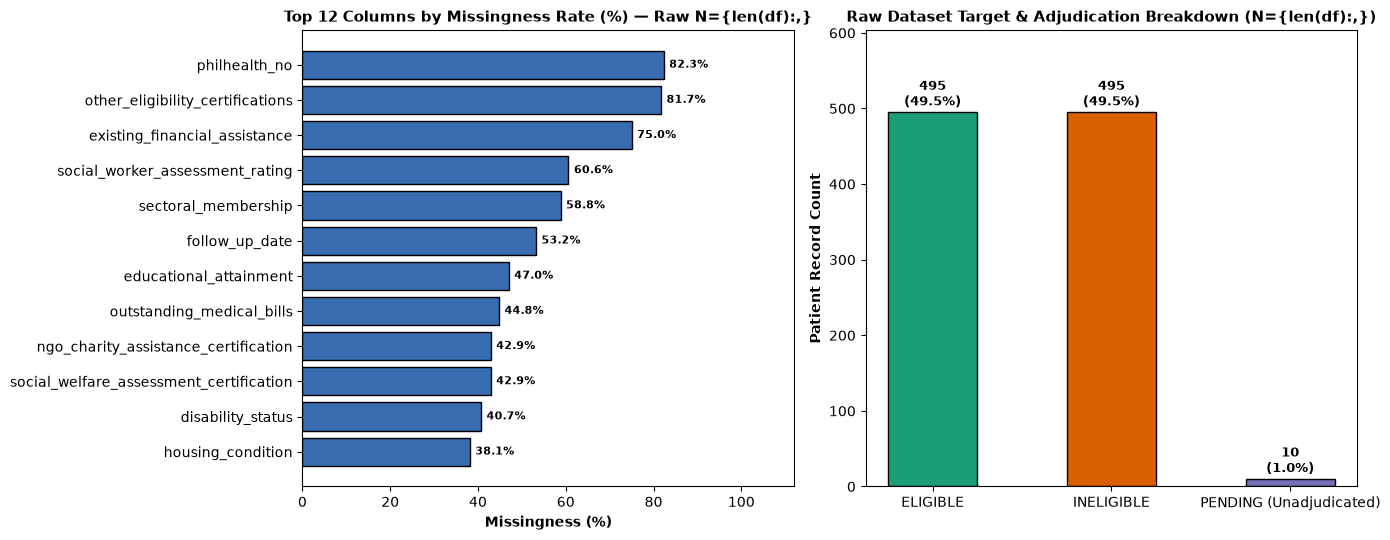

Exported Phase 02 Figure -> c:\Users\ASUS TUF\Desktop\Project in Program\Thesis Project\ofphil-classification-v2\reports\phase_02\visualizations\data_quality_missingness_and_target.png


In [39]:
# --- CHAPTER 4 VISUALIZATION: Data Quality, Missingness & Raw Target Audit ---
import matplotlib.pyplot as plt
VIZ_DIR = PROJECT_ROOT / 'reports' / 'phase_02' / 'visualizations'
VIZ_DIR.mkdir(parents=True, exist_ok=True)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
top12_miss = profile_df.sort_values('null_percentage', ascending=False).head(12).iloc[::-1]
bars1 = ax1.barh(top12_miss['column_name'], top12_miss['null_percentage'], color='#386cb0', edgecolor='black')
ax1.set_title('Top 12 Columns by Missingness Rate (%) — Raw N={len(df):,}', fontsize=11, fontweight='bold')
ax1.set_xlabel('Missingness (%)', fontsize=10, fontweight='bold')
ax1.set_xlim(0, 112)
for b in bars1:
    w = b.get_width()
    ax1.annotate(f'{w:.1f}%', xy=(w, b.get_y() + b.get_height()/2), xytext=(4, 0), textcoords='offset points', va='center', fontsize=8, fontweight='bold')
tgt_s = df['eligibility'].fillna('PENDING (Unadjudicated)').value_counts()
bars2 = ax2.bar(tgt_s.index, tgt_s.values, color=['#1b9e77', '#d95f02', '#7570b3'][:len(tgt_s)], width=0.5, edgecolor='black')
ax2.set_title('Raw Dataset Target & Adjudication Breakdown (N={len(df):,})', fontsize=11, fontweight='bold')
ax2.set_ylabel('Patient Record Count', fontsize=10, fontweight='bold')
ax2.set_ylim(0, max(tgt_s.values) * 1.22)
for b in bars2:
    h = b.get_height()
    ax2.annotate(f'{int(h)}\n({h/len(df)*100:.1f}%)', xy=(b.get_x()+b.get_width()/2, h), xytext=(0, 5), textcoords='offset points', ha='center', fontsize=9, fontweight='bold')
plt.tight_layout()
fig.savefig(VIZ_DIR / 'data_quality_missingness_and_target.png', dpi=300, bbox_inches='tight')
fig.savefig(VIZ_DIR / 'data_quality_missingness_and_target.pdf', bbox_inches='tight')
plt.show()
plt.close(fig)
print(f'Exported Phase 02 Figure -> {VIZ_DIR / "data_quality_missingness_and_target.png"}')
